# Tres formas de curva en torno a un tamaño medio: Rosin-Rammler, Swebrec y la composición de zona de trituración, y el tope en el bloque in situ

**Pregunta:** ¿Concuerdan las tres formas de curva una vez fijado el tamaño medio, y qué cambia el tope del bloque?

**Nivel 2: El método en la práctica** · Requiere: 03-size-distribution/01-from-a-mean-size-to-a-curve · Tiempo de lectura: unos 35 minutos

## Objetivos

Rosin-Rammler tiene dos debilidades conocidas: subestima los finos y no tiene límite superior de tamaño. El motor trae dos formas de curva más y un tope estructural frente a ellas. Este notebook construye cada una sobre un solo tiro, repite la comparación en todo tiro con geometría y mide qué hace el tope sobre la única cantidad que registra el corpus.

Al terminar habrá:

- construido las curvas de Rosin-Rammler, Swebrec y zona de trituración del tiro de Enusa desde sus parámetros y leído qué agrega cada una;
- comparado el P20 y el P80 de las tres formas en 91 tiros, cada uno frente a su propio tamaño medio;
- barrido la ondulación de Swebrec y visto dónde mueve los finos y el extremo grueso;
- aplicado el tope en el bloque in situ y puntuado el tamaño medio con y sin tope frente a las mediciones.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
import json
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


CASE = Path("../../../data/derived/real-enusa/case.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| El corpus y los patrones reconstruidos | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| La función de Swebrec | Ouchterlony 2005, https://doi.org/10.1179/037178405x44539, tal como la imprimen Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 10 y 11) | la ecuación se reproduce con cita | `bf.swebrec` |
| El contraejemplo de Swebrec | Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 | solo citado | ninguno (una afirmación en el docstring del propio motor) |
| El caso Enusa, para nombrar su tiro representativo | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json`, campo `representative_blast_id` |

No existe en el corpus ninguna distribución de tamaños medida: solo se mide el tamaño medio de cada tiro. Las tres formas de curva son salida de modelo, y el notebook las compara entre sí y con esa única cantidad medida.

## Método

**Rosin-Rammler** (Amoako, Jha y Zhong 2022, Ec. 5) es la curva de dos parámetros del notebook anterior. **Swebrec** (Ouchterlony 2005, tal como la imprimen Amoako et al. 2022, Ecs. 10 y 11) tiene tres parámetros:

```
P(x) = 1 / (1 + f(x)),   f(x) = [ ln(x_max / x) / ln(x_max / x50) ]^b
```

El límite superior `x_max` fija la cola gruesa (el motor toma el mayor entre bordo y espaciamiento) y la ondulación `b` moldea los finos. Amoako et al. afirman que la función "es capaz de predecir mejor los finos"; el motor trae un contraejemplo a su lado, porque Babaeian et al. 2019 encontraron a Rosin-Rammler más cerca del análisis de imágenes en una mina de bauxita, de modo que Swebrec no se presenta como mejor en todas partes.

**Composición de zona de trituración.** Dos modos de falla actúan a la vez: la fractura por tracción da los fragmentos gruesos y la fractura por compresión y corte alrededor del taladro da los finos. El motor mezcla por masa una rama gruesa de Rosin-Rammler con una segunda rama más fina. La estructura proviene de Amoako et al. 2022, pero sus tres constantes (tamaño de cruce, uniformidad de los finos y fracción de finos) no están publicadas en ninguna fuente disponible para este trabajo, así que son valores de partida plausibles y cada resultado lo dice.

**Tope en el bloque in situ.** Una voladura rompe bloques y no los funde, de modo que la masa que una curva pone sobre el tamaño de bloque in situ `XB` se lee como bloques sin romper en `XB`: `P_tope(x) = P(x)` bajo `XB` y 1 desde `XB`. Es una decisión de modelado declarada del motor, no una relación publicada. Qué mirar: si las tres formas difieren en el centro o en las colas, qué parámetro mueve qué, y si el tope mejora el único número que se puede verificar.

### Paso 1: el tiro y los parámetros de cada forma

La celda toma el tiro representativo del caso Enusa, le pide a la ecuación clásica su tamaño medio y al patrón su índice de uniformidad, y reúne todos los parámetros que necesitan las tres formas de curva. La tabla es el contrato de la comparación: las tres formas comparten el mismo `x50`, y cada una agrega solo lo que lista su fila.

In [2]:
# El tiro representativo de Enusa, su tamaño medio clásico y los parámetros que toma cada forma de curva
blast_id = json.loads(CASE.read_text(encoding="utf-8"))["representative_blast_id"]
blast = next(b for b in train if b.blast_id == blast_id)
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m
n_index = bf.cunningham_uniformity_index(pattern)
x_max = max(pattern.burden_m, pattern.spacing_m)
undulation = bf.Swebrec().undulation
crush = bf.classical.CrushZoneParameters()

rows = [
    ("las tres", "tamaño medio x50", f"{x50:.4f} m"),
    ("Rosin-Rammler", "índice de uniformidad n", f"{n_index:.4f}"),
    ("Swebrec", "tamaño máximo x_max (el mayor entre B y S)", f"{x_max:.3f} m"),
    ("Swebrec", "ondulación b, valor por defecto del motor", f"{undulation}"),
    ("zona de trituración", "tamaño de cruce", f"{crush.crossover_m} m"),
    ("zona de trituración", "uniformidad de los finos", f"{crush.fines_uniformity}"),
    ("zona de trituración", "fracción de finos", f"{crush.fines_fraction}"),
    ("tiro", "bloque in situ XB", f"{blast.XB_m} m"),
]
show_table(["forma de curva", "parámetro", "valor"], rows)

forma de curva,parámetro,valor
las tres,tamaño medio x50,0.4399 m
Rosin-Rammler,índice de uniformidad n,0.6321
Swebrec,tamaño máximo x_max (el mayor entre B y S),5.579 m
Swebrec,"ondulación b, valor por defecto del motor",2.0
zona de trituración,tamaño de cruce,0.01 m
zona de trituración,uniformidad de los finos,0.8
zona de trituración,fracción de finos,0.05
tiro,bloque in situ XB,0.58 m


Las tres formas parten del mismo tamaño medio de 0,4399 m, y cada una agrega solo lo que listan sus filas. El límite superior de Swebrec es 5,579 m, el espaciamiento, muy por encima del bloque in situ de 0,58 m: el bloque es el techo físico de un fragmento, y este parámetro no lo es. Las constantes de la zona de trituración (un cruce en 0,01 m, una uniformidad de finos de 0,8 y una fracción de finos de 0,05) son valores de partida del motor y no números publicados, lo que el paso 4 imprime como una marca. La tabla no dice cuáles valores son correctos para esta roca; solo fija lo que varía la comparación que sigue.

### Paso 2: Rosin-Rammler

`rosin_rammler` toma el tamaño medio y el índice. La celda construye la curva, imprime cuánta masa deja pasando en el último tamaño de la grilla de mallas y en el bloque in situ, y lee los tres percentiles. Esas dos comprobaciones son lo que las otras formas pretenden mejorar.

In [3]:
# Curva 1, Rosin-Rammler: dos parámetros, y los tamaños que implica
rosin = bf.rosin_rammler(x50, n_index)
size_top = rosin.sizes_m[-1]
print(f"Rosin-Rammler pasante en el último tamaño de la grilla ({size_top:.1f} m): {rosin.passing[-1]:.3f}")
print(f"Rosin-Rammler pasante en el bloque in situ ({blast.XB_m} m): {rosin.passing_at(blast.XB_m):.3f}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{rosin.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

Rosin-Rammler pasante en el último tamaño de la grilla (3.0 m): 0.903
Rosin-Rammler pasante en el bloque in situ (0.58 m): 0.562


P20 (m),P50 (m),P80 (m)
0.0732,0.4399,1.6679


Rosin-Rammler llega solo a 0,903 de la masa en el extremo de 3,0 m de la grilla, de modo que cerca de una décima parte de la roca tronada queda en piezas mayores que la malla más grande, y deja 0,562 de la masa bajo el bloque in situ de 0,58 m, así que el resto queda sobre un tamaño que la roca no puede exceder. Su P20, su P50 y su P80 son 0,0732 m, 0,4399 m y 1,6679 m. Son las cifras que las otras dos formas pretenden corregir; no muestran cuánto se equivocan, porque no hay una distribución medida con la cual compararlas.

### Paso 3: Swebrec

`swebrec` toma el tamaño medio, el límite superior y la ondulación. La ecuación llega a 1 en `x_max`, que en este tiro queda más allá de la grilla de mallas de 3 m del motor, así que la celda imprime cuánta masa pasa en el último tamaño de la grilla y en el bloque in situ, y luego lee los mismos tres percentiles.

In [4]:
# Curva 2, Swebrec: el tercer parámetro termina la curva en x_max
swebrec = bf.swebrec(x50, x_max, undulation)
size_top = swebrec.sizes_m[-1]
print(f"Swebrec pasante en el último tamaño de la grilla ({size_top:.1f} m): {swebrec.passing[-1]:.3f}")
print(f"Swebrec pasante en el bloque in situ ({blast.XB_m} m): {swebrec.passing_at(blast.XB_m):.3f}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{swebrec.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

Swebrec pasante en el último tamaño de la grilla (3.0 m): 0.944
Swebrec pasante en el bloque in situ (0.58 m): 0.557


P20 (m),P50 (m),P80 (m)
0.0347,0.4398,1.5666


Swebrec llega a 0,944 de la masa en el extremo de 3,0 m de la grilla frente a 0,903 de Rosin-Rammler, así que su cola gruesa es más corta en ese tamaño, y deja 0,557 bajo el bloque frente a 0,562, de modo que ambas son casi iguales ahí. El cambio está en los finos: el P20 cae de 0,0732 m a 0,0347 m, menos de la mitad, mientras el P50 queda en 0,4398 m y el P80 se mueve solo de 1,6679 m a 1,5666 m. Ese es el comportamiento que describen Amoako, Jha y Zhong, más finos con el mismo tamaño medio, aquí con la ondulación por defecto del motor de 2,0. La celda no muestra que esos finos existan en la roca.

### Paso 4: la composición de zona de trituración

`crush_zone` mezcla la rama gruesa con una rama de finos. La celda la construye con las constantes por defecto del motor, imprime la fracción que pasa en el tamaño de cruce junto a la de Rosin-Rammler, e imprime la marca que dice si las constantes están publicadas.

In [5]:
# Curva 3, zona de trituración: una rama gruesa y una rama de finos mezcladas por masa
crushed = bf.classical.crush_zone(x50, n_index, crush)
at_crossover = crushed.passing_at(crush.crossover_m)
print(f"zona de trituración pasante en el tamaño de cruce ({crush.crossover_m} m): {at_crossover:.3f}")
print(f"Rosin-Rammler pasante en el mismo tamaño: {rosin.passing_at(crush.crossover_m):.3f}")
print(f"constantes publicadas: {crushed.detail['constants_are_published']}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{crushed.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

zona de trituración pasante en el tamaño de cruce (0.01 m): 0.083
Rosin-Rammler pasante en el mismo tamaño: 0.061
constantes publicadas: False


P20 (m),P50 (m),P80 (m)
0.0507,0.3895,1.5845


En el tamaño de cruce de 0,01 m la curva de zona de trituración deja pasar 0,083 de la masa frente a 0,061 de Rosin-Rammler, porque la rama de finos agrega su proporción declarada de roca finamente triturada. La mezcla además mueve la mediana: el P50 es 0,3895 m, bajo el tamaño medio clásico de 0,4399 m, que las otras dos formas dejan intacto, mientras el P20 de 0,0507 m queda entre las otras formas y el P80 es 1,5845 m. La marca imprime False para las constantes publicadas, así que cada número de esta celda depende de tres valores que las fuentes no entregan.

### Paso 5: las tres curvas juntas

La celda superpone las tres curvas en el eje logarítmico de tamaños con el tamaño medio medido y el bloque in situ marcados, y tabula sus percentiles.

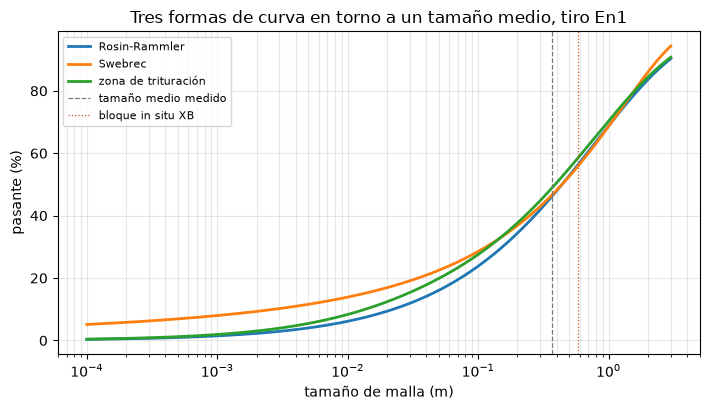

curva,P20 (m),P50 (m),P80 (m)
Rosin-Rammler,0.0732,0.4399,1.6679
Swebrec,0.0347,0.4398,1.5666
zona de trituración,0.0507,0.3895,1.5845


In [6]:
# Las tres curvas en un mismo eje, con el tamaño medio medido y el bloque in situ
curves = {"Rosin-Rammler": rosin, "Swebrec": swebrec, "zona de trituración": crushed}
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for name, curve in curves.items():
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], lw=2, label=name)
ax.axvline(blast.x50_m, color="#777", lw=0.9, ls="--", label="tamaño medio medido")
ax.axvline(blast.XB_m, color="#c05621", lw=0.9, ls=":", label="bloque in situ XB")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%)")
ax.set_title(f"Tres formas de curva en torno a un tamaño medio, tiro {blast_id}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()
rows = [(name, *[f"{curve.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]) for name, curve in curves.items()]
show_table(["curva", "P20 (m)", "P50 (m)", "P80 (m)"], rows)

Las tres curvas coinciden con una diferencia de pocos puntos porcentuales sobre unos 0,1 m y se separan bajo ese tamaño: Swebrec tiene más finos, la mezcla de zona de trituración queda entre ella y Rosin-Rammler. Para este tiro el P20 es 0,0732 m, 0,0347 m y 0,0507 m, el P50 es 0,4399 m, 0,4398 m y 0,3895 m, y el P80 es 1,6679 m, 1,5666 m y 1,5845 m. La figura muestra cómo difieren las formas, no cuál es exacta: la única medición es ese tamaño medio, y tres curvas que coinciden en él no se pueden ordenar con él.

### Paso 6: la misma comparación en 91 tiros

Un tiro puede ser una excepción, así que la celda repite la comparación en todo tiro con geometría a través de los predictores de curva del motor, y expresa el P20 y el P80 como razones respecto del tamaño medio de cada tiro para que tiros de distinta escala compartan un eje.

curva,mediana P20 / x50,mediana P80 / x50
Rosin-Rammler,0.303,2.428
Swebrec,0.072,3.724
zona de trituración,0.256,2.544


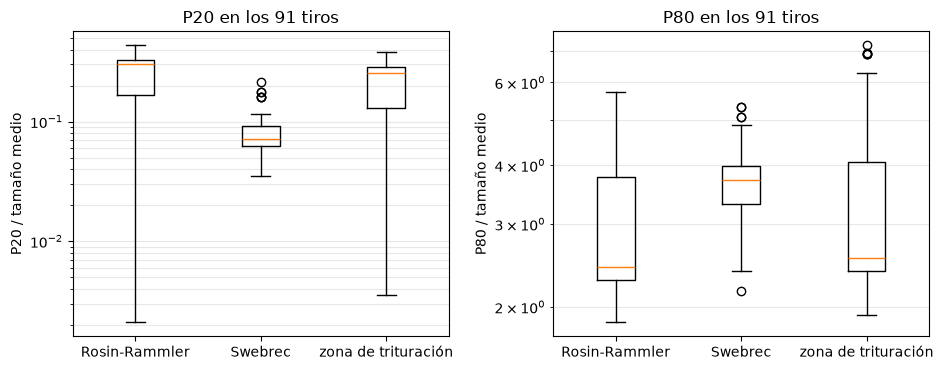

In [7]:
# Las mismas tres formas en cada tiro con geometría, como razones respecto del tamaño medio de cada tiro
arms = {"Rosin-Rammler": bf.KuzRam(), "Swebrec": bf.Swebrec(), "zona de trituración": bf.CrushZone()}
with_geometry = [b for b in train if bf.has_absolute_geometry(b)]
ratios = {}
for name, arm in arms.items():
    curves_all = [arm.distribution(b) for b in with_geometry]
    ratios[name] = {
        "P20": np.array([c.percentile_m(0.2) / c.x50_m for c in curves_all]),
        "P80": np.array([c.percentile_m(0.8) / c.x50_m for c in curves_all]),
    }
rows = [(name, f"{np.median(r['P20']):.3f}", f"{np.median(r['P80']):.3f}") for name, r in ratios.items()]
show_table(["curva", "mediana P20 / x50", "mediana P80 / x50"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
for ax, key in zip(axes, ("P20", "P80")):
    ax.boxplot([r[key] for r in ratios.values()], tick_labels=list(ratios), showfliers=True)
    ax.set_yscale("log")
    ax.set_ylabel(f"{key} / tamaño medio")
    ax.set_title(f"{key} en los 91 tiros")
    ax.grid(alpha=0.3, axis="y", which="both")
fig.tight_layout()
plt.show()

El tiro individual engañaba respecto del P80. En los 91 tiros la mediana del P20 sobre el tamaño medio es 0,303 para Rosin-Rammler, 0,072 para Swebrec y 0,256 para la zona de trituración, así que los finos adicionales de Swebrec se cumplen en general. Pero la mediana del P80 sobre el tamaño medio es 2,428, 3,724 y 2,544, de modo que Swebrec tiene la cola más gruesa para un tiro típico, lo contrario de lo que mostró el tiro de Enusa, porque ese tiro tiene un índice de uniformidad bajo y por lo tanto una curva de Rosin-Rammler ancha. Las cajas de Swebrec son angostas porque esa forma ignora el índice, y los bigotes largos de Rosin-Rammler provienen de los tiros de menor índice; en ellos el P80 se lee en el extremo de 3 m de la grilla, como mostró el notebook anterior.

### Paso 7: el parámetro de ondulación

La ondulación `b` no tiene un ajuste publicado sobre este corpus, así que el valor por defecto del motor es un valor de partida. La celda la barre de 1 a 4 con el tamaño medio y `x_max` sin cambio. El panel izquierdo muestra las curvas, el derecho el P20 y el P80 frente a `b` con los valores de Rosin-Rammler como líneas punteadas.

b,P20 (m),P50 (m),P80 (m)
1.0,0.0002,0.4398,2.9561
1.5,0.0093,0.4398,2.0359
2.0,0.0347,0.4398,1.5666
3.0,0.0989,0.4398,1.1262
4.0,0.1536,0.4398,0.9258


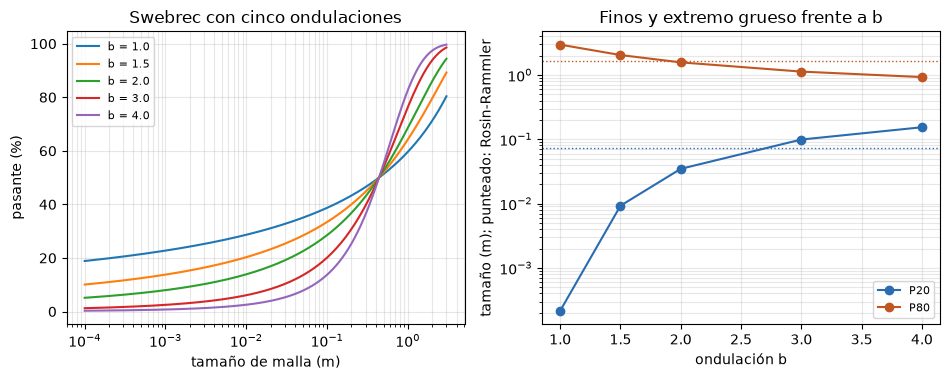

In [8]:
# Variar la ondulación b y leer los finos y el extremo grueso, con el tamaño medio fijo
values = [1.0, 1.5, 2.0, 3.0, 4.0]
family = {b: bf.swebrec(x50, x_max, b) for b in values}
rows = [(b, *[f"{c.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]) for b, c in family.items()]
show_table(["b", "P20 (m)", "P50 (m)", "P80 (m)"], rows)

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for b, curve in family.items():
    left.plot(curve.sizes_m, [100 * p for p in curve.passing], label=f"b = {b}")
left.set_xscale("log")
left.set_xlabel("tamaño de malla (m)")
left.set_ylabel("pasante (%)")
left.set_title("Swebrec con cinco ondulaciones")
left.legend(fontsize=8)
left.grid(alpha=0.3, which="both")
for fraction, color in ((0.2, "#2b6cb0"), (0.8, "#c05621")):
    sizes = [family[b].percentile_m(fraction) for b in values]
    right.plot(values, sizes, "o-", color=color, label=f"P{int(fraction * 100)}")
    right.axhline(rosin.percentile_m(fraction), color=color, ls=":", lw=1)
right.set_yscale("log")
right.set_xlabel("ondulación b")
right.set_ylabel("tamaño (m); punteado: Rosin-Rammler")
right.set_title("Finos y extremo grueso frente a b")
right.legend(fontsize=8)
right.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

Con el tamaño medio fijo en 0,4399 m, la ondulación mueve los dos extremos en sentidos opuestos. De `b` = 1,0 a `b` = 4,0 el P20 sube de 0,0002 m a 0,1536 m, un cambio de tres órdenes de magnitud, y el P80 baja de 2,9561 m a 0,9258 m. El `b` = 2,0 por defecto da 0,0347 m y 1,5666 m, y las líneas punteadas de Rosin-Rammler se cruzan entre `b` = 2,0 y `b` = 3,0 para el P20 y entre `b` = 1,5 y `b` = 2,0 para el P80. El panel derecho muestra que ningún `b` único iguala a Rosin-Rammler en ambos extremos, y no muestra qué `b` ajusta esta roca: el corpus no tiene con qué ajustarlo, y por eso el motor lo trata como una entrada que se fija.

### Paso 8: el tope en un tiro

`cap_at_in_situ_block` fija una curva en 1 desde el tamaño de bloque hacia arriba. La celda lo aplica a las tres curvas de este tiro, tabula el P80 antes y después junto con la masa que cada curva tenía sobre el bloque, y dibuja las curvas antes (discontinuo) y después (continuo).

curva,P80 sin acotar (m),P80 acotado (m),masa sobre XB
Rosin-Rammler,1.668,0.575,43.8%
Swebrec,1.567,0.575,44.3%
zona de trituración,1.585,0.575,41.6%


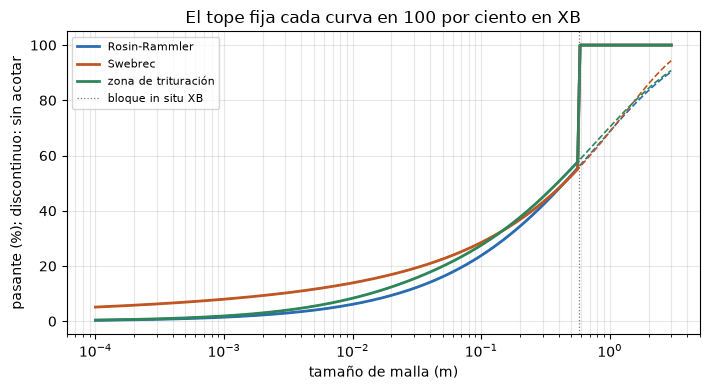

In [9]:
# Acotar cada curva en el bloque in situ de este tiro: la curva antes y después
capped = {name: bf.cap_at_in_situ_block(curve, blast.XB_m) for name, curve in curves.items()}
rows = []
for name, curve in curves.items():
    above = 1 - curve.passing_at(blast.XB_m)
    rows.append((name, f"{curve.percentile_m(0.8):.3f}", f"{capped[name].percentile_m(0.8):.3f}", f"{above:.1%}"))
show_table(["curva", "P80 sin acotar (m)", "P80 acotado (m)", "masa sobre XB"], rows)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
for (name, curve), color in zip(curves.items(), ("#2b6cb0", "#c05621", "#2f855a")):
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], color=color, ls="--", lw=1.2)
    ax.plot(capped[name].sizes_m, [100 * p for p in capped[name].passing], color=color, lw=2, label=name)
ax.axvline(blast.XB_m, color="#777", lw=0.9, ls=":", label="bloque in situ XB")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%); discontinuo: sin acotar")
ax.set_title("El tope fija cada curva en 100 por ciento en XB")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

Antes del tope, las tres curvas ponen 43,8, 44,3 y 41,6 por ciento de la masa sobre el bloque de 0,58 m, lo que es imposible para una voladura que rompe bloques; después, las tres curvas son idénticas sobre el bloque y el P80 de las tres es 0,575 m, el tamaño de la grilla justo bajo el bloque. El tope deja intacto todo lo que está bajo el bloque, de modo que los finos y el P50 de este tiro son los del paso 5. La figura muestra el tope como un escalón duro a 100 por ciento en el tamaño de bloque, una decisión de modelado que asigna el sobretamaño a bloques sin romper y no a los finos, y no muestra si los bloques realmente quedan enteros.

### Paso 9: el tope en 91 tiros

Que el tope importe depende de cuán seguido una curva pone masa sobre su bloque. La celda mide esa proporción para cada forma en todo tiro, y lista los tiros cuyo tamaño medio clásico ya supera su bloque, donde el tope actúa sobre la media y no solo sobre la cola.

curva,mediana de masa sobre XB,máximo
Rosin-Rammler,10.3%,52.0%
Swebrec,21.1%,53.8%
zona de trituración,9.7%,49.4%


tiros cuyo tamaño medio clásico supera su bloque: ['Rc1', 'Rc2', 'Rc3']


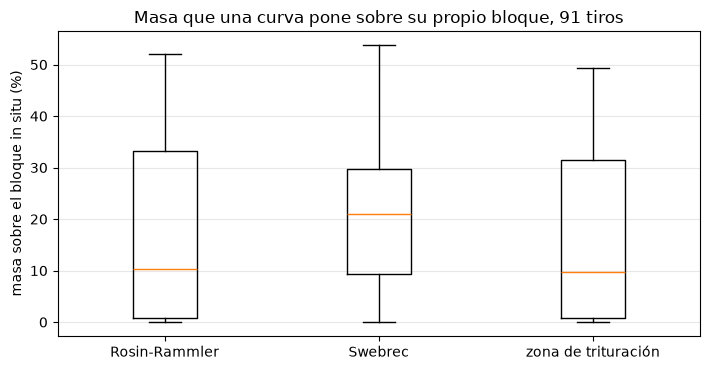

In [10]:
# Cuánta masa pone sobre el bloque cada curva sin acotar, en todo tiro, y dónde el tope actúa sobre la media
share_above = {
    name: np.array([1 - arm.distribution(b).passing_at(b.XB_m) for b in with_geometry])
    for name, arm in arms.items()
}
plain = bf.Kuznetsov()
binding = [b.blast_id for b in with_geometry if plain.predict_one(b).x50_m > b.XB_m]
rows = [(name, f"{np.median(v):.1%}", f"{v.max():.1%}") for name, v in share_above.items()]
show_table(["curva", "mediana de masa sobre XB", "máximo"], rows)
print("tiros cuyo tamaño medio clásico supera su bloque:", binding)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.boxplot([100 * v for v in share_above.values()], tick_labels=list(share_above), showfliers=True)
ax.set_ylabel("masa sobre el bloque in situ (%)")
ax.set_title("Masa que una curva pone sobre su propio bloque, 91 tiros")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

En los 91 tiros la proporción mediana de masa sobre el bloque es 10,3 por ciento para Rosin-Rammler, 21,1 por ciento para Swebrec y 9,7 por ciento para la zona de trituración, con máximos de 52,0, 53,8 y 49,4 por ciento. El tiro de Enusa, con 43,8 por ciento, es entonces un caso alto, no uno típico, y la cola gruesa de Swebrec hace que el tope actúe con más fuerza sobre ella. Solo tres tiros, Rc1, Rc2 y Rc3, tienen un tamaño medio clásico sobre su bloque, de modo que en los otros 88 el tope actúa sobre la cola y nunca sobre la media. La figura muestra cuánta masa discrepa entre las formas, no cuánta de ella es real.

### Paso 10: ¿mejora el tope la única cantidad medida?

El tamaño medio es el único tamaño que mide el corpus, así que es el único lugar donde se puede probar el tope. La celda puntúa el tamaño medio clásico y el acotado frente a los 91 valores medidos con el `score` del motor, y lista los tiros donde el tope cambia la predicción.

In [11]:
# La única cantidad medida: puntuar el tamaño medio con y sin tope en los 91 tiros
cap_arm = bf.InSituCap(plain)
uncapped_predictions = [plain.predict_one(b) for b in with_geometry]
capped_predictions = [cap_arm.predict_one(b) for b in with_geometry]
scores = {
    "tamaño medio clásico": bf.score(with_geometry, uncapped_predictions),
    "clásico, acotado en el bloque": bf.score(with_geometry, capped_predictions),
}
rows = [(name, f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}") for name, s in scores.items()]
show_table(["tamaño medio desde", "r2_identity", "RMSE (m)"], rows)
changed = [(b.blast_id, b.site) for b, p in zip(with_geometry, capped_predictions) if p.detail["cap_binds"]]
print("tiros donde el tope cambia el tamaño medio:", changed)

tamaño medio desde,r2_identity,RMSE (m)
tamaño medio clásico,0.3112,0.1528
"clásico, acotado en el bloque",0.3523,0.1482


tiros donde el tope cambia el tamaño medio: [('Rc1', 'Reocin'), ('Rc2', 'Reocin'), ('Rc3', 'Reocin')]


El tope cambia la predicción exactamente en los tres tiros Rc1, Rc2 y Rc3, y en los 91 tiros sube la varianza explicada respecto de la línea identidad de 0,3112 a 0,3523 y baja la raíz del error cuadrático medio de 0,1528 m a 0,1482 m. Es el único lugar donde una elección de curva se encuentra con una medición, y el tope pasa la prueba: acerca a los valores medidos los tres tiros cuyo tamaño medio clásico excede el bloque medido. El resultado descansa en tres tiros, todos de la campaña Reocin, y los factores de roca clásicos se derivaron de predicciones publicadas del mismo corpus, de modo que la mejora es un indicio y no una ganancia validada.

## Resultados

**Respuesta:** las tres formas concuerdan en el centro y discrepan en las colas, y el tope cambia la cola de toda curva y la media de tres tiros. Para el tiro de Enusa el P50 es 0,4399 m, 0,4398 m y 0,3895 m, pero el P20 es 0,0732 m, 0,0347 m y 0,0507 m. En los 91 tiros la mediana del P20 sobre el tamaño medio es 0,303, 0,072 y 0,256, y la mediana del P80 sobre el tamaño medio es 2,428, 3,724 y 2,544, así que Swebrec tiene a la vez más finos y la cola más gruesa para un tiro típico. Su ondulación sola mueve el P20 de 0,0002 m a 0,1536 m. El tope quita 43,8, 44,3 y 41,6 por ciento de la masa que las tres curvas ponen sobre el bloque de Enusa, y en los 91 tiros actúa sobre la media solo en Rc1, Rc2 y Rc3, lo que sube la varianza explicada de 0,3112 a 0,3523.

**Lo que esto no muestra.** Ninguna de estas curvas se comparó con una distribución de tamaños medida, y las constantes de la zona de trituración no son valores publicados, de modo que las diferencias anteriores son diferencias entre formas de modelo, no diferencias de exactitud. La ondulación de Swebrec no tiene ajuste en este corpus, y la ganancia del tope descansa en tres tiros. Por eso este tema no tiene un notebook de estado del arte: con solo el tamaño medio medido, no hay nada contra qué ordenar las formas.

## Resumen

- Tres formas de curva comparten un tamaño medio y difieren en las colas: Swebrec tiene más finos y, para un tiro típico, el P80 más grueso.
- La ondulación de Swebrec mueve los finos en tres órdenes de magnitud y las constantes de la zona de trituración no son valores publicados; ninguna se puede ajustar en este corpus.
- El tope en el bloque in situ quita sobretamaño que no puede existir y mejora el tamaño medio en los tres tiros donde actúa.
- Siguiente: el tema 04 pasa de lo que predice un modelo a cómo se juzga una predicción.

## Referencias

- Ouchterlony 2005, https://doi.org/10.1179/037178405x44539 (la función de Swebrec)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5, 10 y 11 y la descripción del mecanismo de zona de trituración)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (el contraejemplo de bauxita para Swebrec)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/